# Convolutional Neural Networks on CIFAR-10

This notebook goes with the lecture on convolutional neural networks (CNNs). Lecture 13 trained a small fully connected network on 2-D points. Here a CNN learns to recognize objects in real photos, and the notebook takes it apart: what one convolution computes, how big every layer is, what the trained filters look like, why the network beats Lecture 13's network with a fifth of the weights, and how the same network turns into a detector that scans a whole photo in one pass.

Data: CIFAR-10, 60,000 color photos of 32 × 32 pixels in 10 classes (airplane, automobile, bird, cat, deer, dog, frog, horse, ship, truck). `torchvision` downloads it (about 170 MB) into `data/` the first time. The face crops of the last section are `data/faces1000.npy` and `data/nonfaces1000.npy` from the PCA lecture.

Running time: about 5 minutes on a CPU with 6 cores, 3 minutes with a GPU; an older laptop may need 10 minutes or more. Every training run is seeded, but the exact numbers still change a little from one computer to another (a point or so of accuracy).

In [1]:
import time

import cv2 as cv
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from matplotlib import pyplot as plt

# A GPU if there is one: NVIDIA (cuda), Apple silicon (mps), otherwise the CPU
if torch.cuda.is_available():
    device = torch.device('cuda')
elif torch.backends.mps.is_available():
    device = torch.device('mps')
else:
    device = torch.device('cpu')
print('device:', device)
torch.manual_seed(0)
np.random.seed(0)

device: cuda


## The Data: CIFAR-10

`torchvision.datasets.CIFAR10` keeps the photos as one NumPy array of `uint8` values, `(N, 32, 32, 3)`. PyTorch wants `float` tensors with the channels first, `(N, 3, 32, 32)`, so we convert once: divide by 255 to get 0 to 1, then map to −1 to 1 by subtracting 0.5 and dividing by 0.5 (what `transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))` does in the original PyTorch tutorial). Converting the whole set once, instead of photo by photo in every epoch, makes training several times faster on a CPU.

As in Lecture 13, the 50,000 training photos are split: 45,000 to train on and 5,000 for **validation**, to watch the accuracy while training. The 10,000 test photos are used only at the end.

In [2]:
trainset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True)
testset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True)
classes = trainset.classes
print(classes)
print('training photos:', trainset.data.shape, trainset.data.dtype)

def to_tensor(images_uint8):
    x = torch.tensor(images_uint8).permute(0, 3, 1, 2).float() / 255    # (N, 3, 32, 32), 0 to 1
    return (x - 0.5) / 0.5                                               # -1 to 1

X_all, y_all = to_tensor(trainset.data), torch.tensor(trainset.targets)
X_test, y_test = to_tensor(testset.data), torch.tensor(testset.targets)

split = torch.randperm(50000, generator=torch.Generator().manual_seed(0))
X_train, y_train = X_all[split[:45000]], y_all[split[:45000]]
X_val, y_val = X_all[split[45000:]], y_all[split[45000:]]
print('train', tuple(X_train.shape), ' validation', tuple(X_val.shape), ' test', tuple(X_test.shape))

train_loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(X_train, y_train), batch_size=64, shuffle=True)
val_loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(X_val, y_val), batch_size=1000)
test_loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(X_test, y_test), batch_size=1000)

100%|██████████| 170M/170M [27:06<00:00, 105kB/s]  


['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
training photos: (50000, 32, 32, 3) uint8
train (45000, 3, 32, 32)  validation (5000, 3, 32, 32)  test (10000, 3, 32, 32)


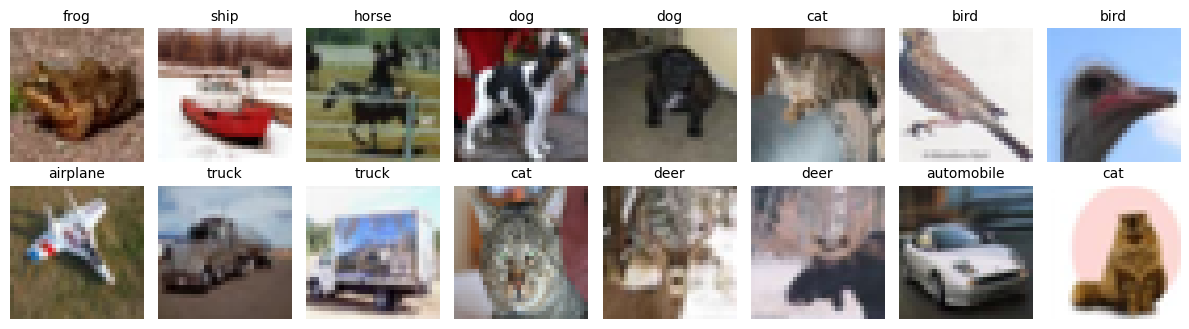

In [3]:
def show(x):
    """A normalized (3, H, W) tensor back to a displayable (H, W, 3) image."""
    return (x.permute(1, 2, 0).cpu().numpy() * 0.5 + 0.5).clip(0, 1)

fig, axs = plt.subplots(2, 8, figsize=(12, 3.4))
for ax, i in zip(axs.flat, range(16)):
    ax.imshow(show(X_train[i]))
    ax.set_title(classes[y_train[i]], fontsize=10)
    ax.axis('off')
plt.tight_layout()
plt.show()

## A Convolution You Have Already Computed

A convolutional layer slides small filters over the image, exactly like `cv.filter2D` in the filtering and edge detection lectures. Here is the Sobel x kernel applied to one CIFAR photo (in grayscale) twice: with OpenCV, and with PyTorch's `F.conv2d`, the function a convolutional layer calls.

Two details. `F.conv2d` wants 4-D tensors: (images, channels, height, width) for the input and (filters, channels, height, width) for the kernel. And without padding it only computes the positions where the whole 3 × 3 window fits, so a 32 × 32 image gives a 30 × 30 result; `cv.filter2D` pads the border and returns 32 × 32. We compare the inside.

OpenCV: (32, 32)  PyTorch: (30, 30)
largest difference inside the border: 0.0


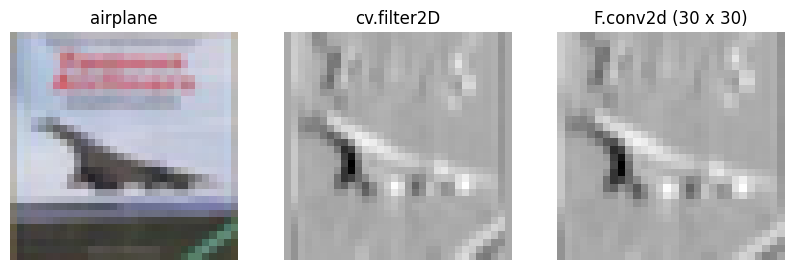

In [4]:
img = show(X_test[3])                                  # a test photo, (32, 32, 3), 0 to 1
gray = cv.cvtColor(img.astype(np.float32), cv.COLOR_RGB2GRAY)

sobel_x = np.array([[-1, 0, 1],
                    [-2, 0, 2],
                    [-1, 0, 1]], dtype=np.float32)

opencv = cv.filter2D(gray, cv.CV_32F, sobel_x)                                   # (32, 32)
torch_out = F.conv2d(torch.tensor(gray)[None, None], torch.tensor(sobel_x)[None, None])[0, 0].numpy()   # (30, 30)
print('OpenCV:', opencv.shape, ' PyTorch:', torch_out.shape)
print('largest difference inside the border:', np.abs(opencv[1:-1, 1:-1] - torch_out).max())

fig, axs = plt.subplots(1, 3, figsize=(10, 3.4))
axs[0].imshow(img); axs[0].set_title(classes[y_test[3]])
axs[1].imshow(opencv, cmap='gray'); axs[1].set_title('cv.filter2D')
axs[2].imshow(torch_out, cmap='gray'); axs[2].set_title('F.conv2d (30 x 30)')
for ax in axs:
    ax.axis('off')
plt.show()

**Convolution or correlation?** The two functions agree, and neither flips the kernel: both compute *correlation*. A true convolution flips the kernel left to right and top to bottom first, which turns Sobel x into minus Sobel x. Deep learning calls the operation convolution anyway. For a layer it makes no difference, because the network learns its kernels: a flipped version of a learned kernel is just a different set of learned numbers.

In [5]:
flipped = sobel_x[::-1, ::-1].copy()
print(flipped)
true_convolution = F.conv2d(torch.tensor(gray)[None, None], torch.tensor(flipped)[None, None])[0, 0].numpy()
print('true convolution = -correlation here:', np.allclose(true_convolution, -torch_out, atol=1e-5))

[[ 1.  0. -1.]
 [ 2.  0. -2.]
 [ 1.  0. -1.]]
true convolution = -correlation here: True


**Three channels.** A color image has three channels, so a filter of a convolutional layer has three slices, one per channel. It multiplies each slice with its channel, adds **all** the products, and adds one bias. One filter gives one output map, whatever the number of input channels. Here the three slices are all Sobel x and the bias is 0.5, so the result must be the sum of three per-channel `cv.filter2D` results, plus 0.5.

In [6]:
layer = nn.Conv2d(in_channels=3, out_channels=1, kernel_size=3)
print('weight shape (filters, channels, height, width):', tuple(layer.weight.shape), ' bias shape:', tuple(layer.bias.shape))
with torch.no_grad():
    layer.weight[:] = torch.tensor(sobel_x)               # the same 3 x 3 slice for R, G and B
    layer.bias[:] = 0.5
    out = layer(torch.tensor(img).permute(2, 0, 1)[None])[0, 0].numpy()

by_hand = sum(cv.filter2D(np.ascontiguousarray(img[:, :, c]).astype(np.float32), cv.CV_32F, sobel_x) for c in range(3)) + 0.5
print('largest difference:', np.abs(by_hand[1:-1, 1:-1] - out).max())

weight shape (filters, channels, height, width): (1, 3, 3, 3)  bias shape: (1,)
largest difference: 9.536743e-07


## The Network, Layer by Layer

This is the network of the original PyTorch tutorial, a small version of LeNet-5 (1998). Its first layer, `nn.Conv2d(3, 6, 5)`, is the lecture's running example: six 5 × 5 × 3 filters sliding over a 32 × 32 × 3 image, giving six 28 × 28 activation maps. Every convolution is followed by a ReLU, and every ReLU by 2 × 2 max pooling, which halves the height and the width. The last three layers are the fully connected network of Lecture 13: the 16 × 5 × 5 = 400 numbers left at the end are flattened into one vector and classified.

In [7]:
class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 6, 5)       # input channels, output channels (filters), kernel size
        self.pool = nn.MaxPool2d(2, 2)        # 2 x 2 windows, stride 2
        self.conv2 = nn.Conv2d(6, 16, 5)
        self.fc1 = nn.Linear(16 * 5 * 5, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))  # 3 x 32 x 32 -> 6 x 28 x 28 -> 6 x 14 x 14
        x = self.pool(F.relu(self.conv2(x)))  # -> 16 x 10 x 10 -> 16 x 5 x 5
        x = torch.flatten(x, 1)               # -> 400 numbers per image (dimension 0 is the batch)
        x = F.relu(self.fc1(x))               # -> 120
        x = F.relu(self.fc2(x))               # -> 84
        return self.fc3(x)                    # -> 10 class scores

net = Net()
print(net)

Net(
  (conv1): Conv2d(3, 6, kernel_size=(5, 5), stride=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
  (fc1): Linear(in_features=400, out_features=120, bias=True)
  (fc2): Linear(in_features=120, out_features=84, bias=True)
  (fc3): Linear(in_features=84, out_features=10, bias=True)
)


Run one image through the layers one at a time and print the shape after each step. The convolution sizes follow the lecture's formula, (N − F + 2P) / S + 1: (32 − 5) / 1 + 1 = 28, and (14 − 5) / 1 + 1 = 10.

A layer's parameters are its weights and biases. A convolutional layer with K filters of size F × F over C input channels has K × (F × F × C + 1) of them; a fully connected layer with n inputs and m outputs has m × (n + 1).

In [8]:
x = X_test[:1]
print(f'{"input":8s} {str(tuple(x.shape[1:])):14s}')
steps = [('conv1', net.conv1), ('relu', F.relu), ('pool', net.pool), ('conv2', net.conv2), ('relu', F.relu), ('pool', net.pool),
         ('flatten', lambda t: torch.flatten(t, 1)), ('fc1', net.fc1), ('relu', F.relu), ('fc2', net.fc2), ('relu', F.relu), ('fc3', net.fc3)]
with torch.no_grad():
    for name, step in steps:
        x = step(x)
        n_params = sum(p.numel() for p in step.parameters()) if isinstance(step, nn.Module) else 0
        print(f'{name:8s} {str(tuple(x.shape[1:])):14s} {n_params:8,d} parameters')

total = sum(p.numel() for p in net.parameters())
conv = sum(p.numel() for p in list(net.conv1.parameters()) + list(net.conv2.parameters()))
print(f'TOTAL parameters {total:,d}; convolutional layers {conv:,d} ({100 * conv / total:.1f}%); fc1 alone {sum(p.numel() for p in net.fc1.parameters()):,d} ({100 * sum(p.numel() for p in net.fc1.parameters()) / total:.0f}%)')

input    (3, 32, 32)   
conv1    (6, 28, 28)         456 parameters
relu     (6, 28, 28)           0 parameters
pool     (6, 14, 14)           0 parameters
conv2    (16, 10, 10)      2,416 parameters
relu     (16, 10, 10)          0 parameters
pool     (16, 5, 5)            0 parameters
flatten  (400,)                0 parameters
fc1      (120,)           48,120 parameters
relu     (120,)                0 parameters
fc2      (84,)            10,164 parameters
relu     (84,)                 0 parameters
fc3      (10,)               850 parameters
TOTAL parameters 62,006; convolutional layers 2,872 (4.6%); fc1 alone 48,120 (78%)


**Check the formula by hand.** conv1 has 6 × (5 × 5 × 3 + 1) = 6 × 76 = 456 parameters, the number on the lecture slide. conv2 has 16 × (5 × 5 × 6 + 1) = 2,416. The two convolutional layers, which look at the pixels, hold under 5% of the network; the first fully connected layer holds more than three quarters.

## Training

The same loop as in Lecture 13: forward pass, cross-entropy loss, `loss.backward()`, one step of stochastic gradient descent (here with momentum, which keeps part of the previous step's direction). After every epoch, one pass over the 45,000 training photos, we measure the accuracy on the validation photos. `model.train()` and `model.eval()` make no difference for this network, but they matter for layers such as dropout and batch normalization, so it is a good habit.

The `augment` and `pixel_order` arguments are used in later sections; leave them out for now.

In [9]:
def accuracy(model, loader, pixel_order=None):
    model.eval()
    correct = 0
    with torch.no_grad():
        for xb, yb in loader:
            if pixel_order is not None:
                xb = shuffle_pixels(xb, pixel_order)
            correct += (model(xb.to(device)).argmax(1).cpu() == yb).sum().item()
    return correct / len(loader.dataset)


def train(model, epochs=10, lr=0.01, augment=False, pixel_order=None, seed=0):
    torch.manual_seed(seed)
    model.to(device)
    optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9)
    history = []
    for epoch in range(epochs):
        model.train()
        start, total_loss, correct = time.time(), 0.0, 0
        for xb, yb in train_loader:
            if augment:
                xb = random_crop_and_flip(xb)
            if pixel_order is not None:
                xb = shuffle_pixels(xb, pixel_order)
            xb, yb = xb.to(device), yb.to(device)
            scores = model(xb)
            loss = F.cross_entropy(scores, yb)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(yb)
            correct += (scores.argmax(1) == yb).sum().item()
        train_acc, val_acc = correct / len(X_train), accuracy(model, val_loader, pixel_order)
        history.append((total_loss / len(X_train), train_acc, val_acc))
        print(f'epoch {epoch + 1:2d}: loss {total_loss / len(X_train):.3f}  train accuracy {train_acc:.1%}  validation accuracy {val_acc:.1%}  ({time.time() - start:.1f} s)')
    return history

In [10]:
torch.manual_seed(0)
net = Net()
history = train(net, epochs=10)

epoch  1: loss 1.886  train accuracy 29.6%  validation accuracy 38.3%  (2.9 s)
epoch  2: loss 1.450  train accuracy 47.2%  validation accuracy 50.2%  (2.5 s)
epoch  3: loss 1.300  train accuracy 53.2%  validation accuracy 53.2%  (2.4 s)
epoch  4: loss 1.208  train accuracy 57.1%  validation accuracy 55.5%  (2.5 s)
epoch  5: loss 1.115  train accuracy 60.5%  validation accuracy 59.9%  (2.3 s)
epoch  6: loss 1.050  train accuracy 62.9%  validation accuracy 61.7%  (2.4 s)
epoch  7: loss 0.998  train accuracy 64.6%  validation accuracy 58.8%  (1.9 s)
epoch  8: loss 0.942  train accuracy 66.7%  validation accuracy 61.6%  (3.2 s)
epoch  9: loss 0.904  train accuracy 68.0%  validation accuracy 59.8%  (1.9 s)
epoch 10: loss 0.865  train accuracy 69.4%  validation accuracy 60.8%  (1.9 s)


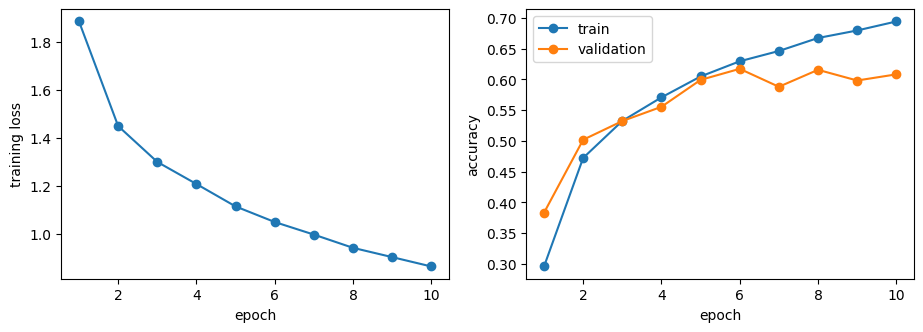

In [11]:
h = np.array(history)
fig, axs = plt.subplots(1, 2, figsize=(11, 3.5))
axs[0].plot(range(1, len(h) + 1), h[:, 0], 'o-'); axs[0].set_xlabel('epoch'); axs[0].set_ylabel('training loss')
axs[1].plot(range(1, len(h) + 1), h[:, 1], 'o-', label='train')
axs[1].plot(range(1, len(h) + 1), h[:, 2], 'o-', label='validation')
axs[1].set_xlabel('epoch'); axs[1].set_ylabel('accuracy'); axs[1].legend()
plt.show()

The training accuracy keeps rising while the validation accuracy levels off: the gap between them is the network starting to memorize its training photos (overfitting, Lecture 13). Now the test set, once.

In [12]:
cnn_test = accuracy(net, test_loader)
print(f'CNN TEST accuracy: {cnn_test:.1%}  (chance is 10%)')
torch.save(net.state_dict(), 'output/cifar_net.pth')    # the trained weights, to load again later with net.load_state_dict

CNN TEST accuracy: 61.5%  (chance is 10%)


### Class by Class

The **confusion matrix** counts, for every true class (row), how often each class was predicted (column). The diagonal holds the correct answers.

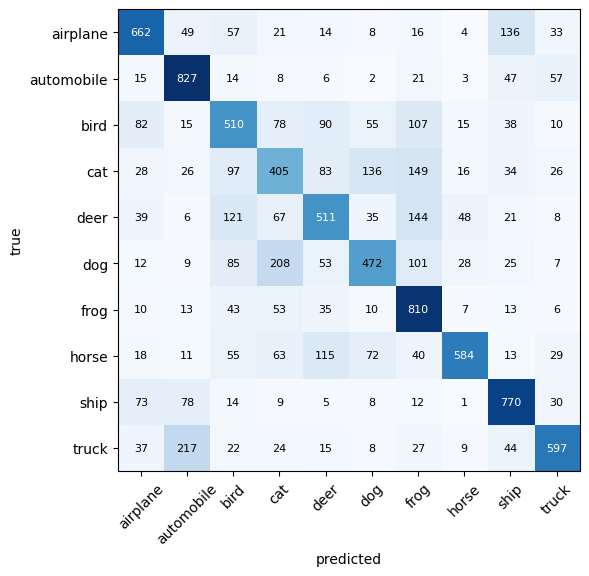

airplane   66%
automobile 83%
bird       51%
cat        40%
deer       51%
dog        47%
frog       81%
horse      58%
ship       77%
truck      60%
MOST CONFUSED: 217 trucks called automobile


In [13]:
net.eval()
with torch.no_grad():
    predicted = torch.cat([net(xb.to(device)).argmax(1).cpu() for xb, _ in test_loader])
confusion = np.zeros((10, 10), dtype=int)
for t, p in zip(y_test.numpy(), predicted.numpy()):
    confusion[t, p] += 1

plt.figure(figsize=(7, 6))
plt.imshow(confusion, cmap='Blues')
for t in range(10):
    for p in range(10):
        plt.text(p, t, confusion[t, p], ha='center', va='center', fontsize=8, color='white' if confusion[t, p] > 500 else 'black')
plt.xticks(range(10), classes, rotation=45); plt.yticks(range(10), classes)
plt.xlabel('predicted'); plt.ylabel('true')
plt.show()

for c in range(10):
    print(f'{classes[c]:10s} {confusion[c, c] / confusion[c].sum():.0%}')
off = confusion - np.diag(np.diag(confusion))
t, p = np.unravel_index(off.argmax(), off.shape)
print(f'MOST CONFUSED: {confusion[t, p]} {classes[t]}s called {classes[p]}')

## Why Convolution? Lecture 13's Network on the Same Photos

Lecture 13's 2-layer network flattens the photo into 3,072 numbers and connects every one of them to each of 100 hidden units: 3,072 × 100 + 100 + 100 × 10 + 10 = 308,310 parameters, five times as many as the CNN. Same data, same training loop.

In [14]:
mlp = nn.Sequential(nn.Flatten(), nn.Linear(3072, 100), nn.ReLU(), nn.Linear(100, 10))
print(f'{sum(p.numel() for p in mlp.parameters()):,d} parameters')
torch.manual_seed(0)
mlp = nn.Sequential(nn.Flatten(), nn.Linear(3072, 100), nn.ReLU(), nn.Linear(100, 10))
train(mlp, epochs=10)
mlp_test = accuracy(mlp, test_loader)
print(f'MLP TEST accuracy: {mlp_test:.1%}   CNN: {cnn_test:.1%}')

308,310 parameters
epoch  1: loss 1.683  train accuracy 40.5%  validation accuracy 44.9%  (1.9 s)
epoch  2: loss 1.491  train accuracy 47.8%  validation accuracy 46.8%  (2.0 s)
epoch  3: loss 1.406  train accuracy 50.7%  validation accuracy 48.2%  (1.8 s)
epoch  4: loss 1.354  train accuracy 52.6%  validation accuracy 49.6%  (1.8 s)
epoch  5: loss 1.304  train accuracy 54.4%  validation accuracy 48.7%  (1.8 s)
epoch  6: loss 1.270  train accuracy 55.6%  validation accuracy 50.6%  (1.8 s)
epoch  7: loss 1.233  train accuracy 56.8%  validation accuracy 50.0%  (1.8 s)
epoch  8: loss 1.207  train accuracy 57.8%  validation accuracy 48.8%  (1.8 s)
epoch  9: loss 1.178  train accuracy 58.7%  validation accuracy 49.7%  (1.8 s)
epoch 10: loss 1.149  train accuracy 59.7%  validation accuracy 49.3%  (1.8 s)
MLP TEST accuracy: 51.5%   CNN: 61.5%


**The pixel-shuffle test.** What does the CNN know that the MLP does not? Pick one random reordering of the 1,024 pixel positions and apply it to every photo, in training and in testing alike. The photos become noise to us, but no information is lost: the same reordering could be undone.

Q: Which network should suffer?

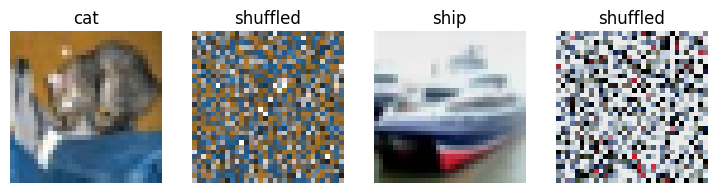

In [15]:
pixel_order = torch.randperm(32 * 32, generator=torch.Generator().manual_seed(1))

def shuffle_pixels(x, order):
    """Move the pixels of every image (all channels alike) to new positions; the same order for every image."""
    n, c, h, w = x.shape
    return x.reshape(n, c, h * w)[:, :, order].reshape(n, c, h, w)

fig, axs = plt.subplots(1, 4, figsize=(9, 2.6))
for k, i in enumerate((0, 1)):
    axs[2 * k].imshow(show(X_test[i])); axs[2 * k].set_title(classes[y_test[i]])
    axs[2 * k + 1].imshow(show(shuffle_pixels(X_test[i:i + 1], pixel_order)[0])); axs[2 * k + 1].set_title('shuffled')
for ax in axs:
    ax.axis('off')
plt.show()

In [16]:
results = {}
for name, make in (('MLP', lambda: nn.Sequential(nn.Flatten(), nn.Linear(3072, 100), nn.ReLU(), nn.Linear(100, 10))), ('CNN', Net)):
    torch.manual_seed(0)
    model = make()
    print(name, 'on shuffled pixels')
    train(model, epochs=10, pixel_order=pixel_order)
    results[name] = accuracy(model, test_loader, pixel_order)
print(f'SHUFFLED TEST accuracy: MLP {results["MLP"]:.1%} (was {mlp_test:.1%}),  CNN {results["CNN"]:.1%} (was {cnn_test:.1%})')

MLP on shuffled pixels
epoch  1: loss 1.684  train accuracy 40.4%  validation accuracy 45.1%  (2.2 s)
epoch  2: loss 1.490  train accuracy 47.9%  validation accuracy 46.8%  (2.1 s)
epoch  3: loss 1.405  train accuracy 50.6%  validation accuracy 48.0%  (2.1 s)
epoch  4: loss 1.353  train accuracy 52.5%  validation accuracy 48.8%  (2.2 s)
epoch  5: loss 1.304  train accuracy 54.4%  validation accuracy 48.6%  (2.1 s)
epoch  6: loss 1.273  train accuracy 55.4%  validation accuracy 49.2%  (2.1 s)
epoch  7: loss 1.235  train accuracy 56.9%  validation accuracy 49.9%  (2.0 s)
epoch  8: loss 1.209  train accuracy 57.6%  validation accuracy 50.2%  (2.0 s)
epoch  9: loss 1.176  train accuracy 58.7%  validation accuracy 50.1%  (2.0 s)
epoch 10: loss 1.148  train accuracy 59.8%  validation accuracy 49.9%  (2.1 s)
CNN on shuffled pixels
epoch  1: loss 2.061  train accuracy 21.5%  validation accuracy 23.3%  (3.1 s)
epoch  2: loss 1.813  train accuracy 33.1%  validation accuracy 36.6%  (3.1 s)
epoch 

The MLP hardly notices: it never knew which pixels were neighbors, since every input has its own weights anyway. The CNN loses its whole advantage and ends up below the MLP. Its 5 × 5 filters assume that a pixel's neighbors are the pixels next to it, and that the same pattern means the same thing anywhere in the image. Those two assumptions (locality and shared weights) are what a convolutional layer adds, and on real photos they are true.

## Looking Inside the Network

**The filters.** conv1 has six filters of size 5 × 5 × 3. Shown as tiny color images (each stretched to the full gray range), they are what the first layer looks for. With only six filters and 32 × 32 photos they are rough, but some are recognizably edge and color detectors, like the first-layer filters of large networks.

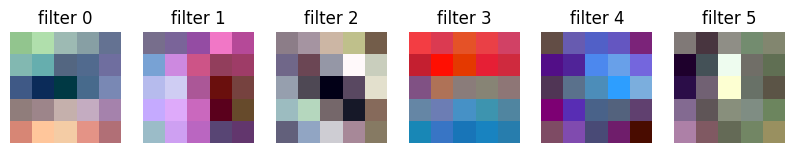

In [17]:
w = net.conv1.weight.detach().cpu()                       # (6, 3, 5, 5)
fig, axs = plt.subplots(1, 6, figsize=(10, 2))
for k, ax in enumerate(axs):
    f = w[k].permute(1, 2, 0).numpy()
    ax.imshow((f - f.min()) / (f.max() - f.min()), interpolation='nearest')
    ax.set_title(f'filter {k}'); ax.axis('off')
plt.show()

**The activation maps.** The outputs of conv1 (after the ReLU) for one test photo: six 28 × 28 maps, one per filter, bright where the filter's pattern is present. Then the sixteen 10 × 10 maps of conv2, which combine conv1's maps and are already harder to read.

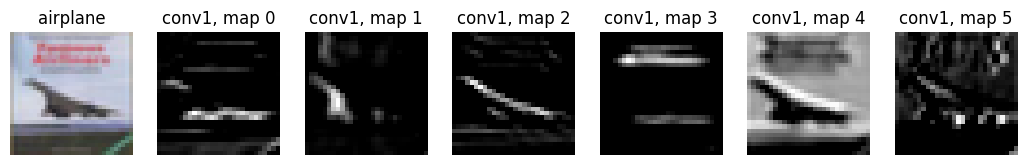

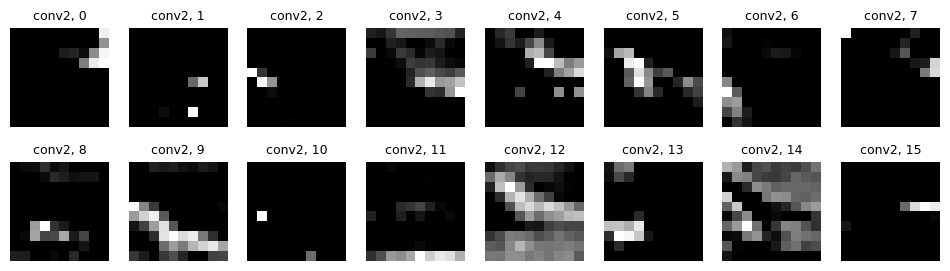

In [18]:
i = 3
with torch.no_grad():
    a1 = F.relu(net.conv1(X_test[i:i + 1].to(device)))[0].cpu()               # (6, 28, 28)
    a2 = F.relu(net.conv2(net.pool(F.relu(net.conv1(X_test[i:i + 1].to(device))))))[0].cpu()   # (16, 10, 10)

fig, axs = plt.subplots(1, 7, figsize=(13, 2.2))
axs[0].imshow(show(X_test[i])); axs[0].set_title(classes[y_test[i]])
for k in range(6):
    axs[k + 1].imshow(a1[k], cmap='gray'); axs[k + 1].set_title(f'conv1, map {k}')
for ax in axs:
    ax.axis('off')
plt.show()

fig, axs = plt.subplots(2, 8, figsize=(12, 3.2))
for k, ax in enumerate(axs.flat):
    ax.imshow(a2[k], cmap='gray'); ax.set_title(f'conv2, {k}', fontsize=9); ax.axis('off')
plt.show()

**Shift the photo, and the maps shift with it.** A convolutional layer applies the same filter everywhere, so moving the input moves the output by the same amount and changes nothing else (except at the border, where new pixels enter). This is *translation equivariance*. Here the photo moves 4 pixels to the right.

In [19]:
x = X_test[i:i + 1]
shifted = torch.roll(x, shifts=4, dims=3)                  # 4 pixels to the right (the right edge wraps around to the left)
with torch.no_grad():
    m = net.conv1(x.to(device)).cpu()
    m_shifted = net.conv1(shifted.to(device)).cpu()
inside = (m_shifted[..., 4:] - m[..., :-4]).abs()[..., 4:].max().item()   # compare away from the wrapped columns
print(f'largest difference between the shifted map and the map of the shifted photo, inside: {inside:.2g}')

largest difference between the shifted map and the map of the shifted photo, inside: 0


The whole network is not equivariant: its pooling and fully connected layers turn the maps into one answer, which should not move at all (*invariance*). It is only roughly invariant. The probabilities of the true class as the photo slides 0 to 6 pixels to the right (the empty strip on the left filled with the edge color):

In [20]:
def shift_right(x, s):
    if s == 0:
        return x
    return torch.cat([x[..., :1].expand(-1, -1, -1, s), x[..., :-s]], dim=3)

net.eval()
with torch.no_grad():
    for s in range(7):
        p = F.softmax(net(shift_right(X_test[:8], s).to(device)), dim=1).cpu()
        print(f'shift {s}: ' + '  '.join(f'{p[k, y_test[k]]:.2f}' for k in range(8)))

shift 0: 0.71  0.96  0.17  0.28  0.97  0.87  0.03  0.88
shift 1: 0.57  0.97  0.17  0.28  0.86  0.91  0.01  0.90
shift 2: 0.65  0.94  0.24  0.16  0.67  0.89  0.13  0.76
shift 3: 0.79  0.98  0.42  0.36  0.78  0.92  0.02  0.75
shift 4: 0.69  0.98  0.41  0.23  0.77  0.86  0.06  0.37
shift 5: 0.68  0.96  0.43  0.39  0.83  0.90  0.07  0.25
shift 6: 0.76  0.62  0.45  0.28  0.73  0.92  0.19  0.12


## Data Augmentation

The network saw each training photo the same way in every epoch, which makes memorizing easy. **Data augmentation** shows it a slightly different version every time: here a random crop (pad the photo by 4 pixels on each side, then cut out a random 32 × 32 window, a shift of up to 4 pixels) and a mirror image half of the time. A cat shifted or mirrored is still a cat, so the label stays the same. `torchvision.transforms.RandomCrop(32, padding=4)` and `transforms.RandomHorizontalFlip()` do the same photo by photo; Lecture 15 uses them.

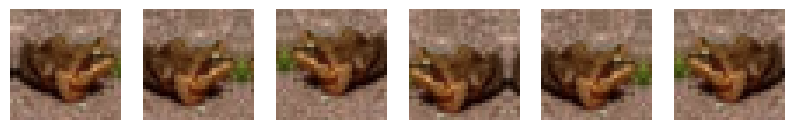

In [21]:
def random_crop_and_flip(x, pad=4):
    n = len(x)
    padded = F.pad(x, (pad, pad, pad, pad), mode='reflect')
    dy, dx = torch.randint(0, 2 * pad + 1, (2, n))
    out = torch.stack([padded[k, :, dy[k]:dy[k] + 32, dx[k]:dx[k] + 32] for k in range(n)])
    flip = torch.rand(n) < 0.5
    out[flip] = out[flip].flip(3)
    return out

fig, axs = plt.subplots(1, 6, figsize=(10, 2))
torch.manual_seed(3)
for ax in axs:
    ax.imshow(show(random_crop_and_flip(X_train[:1])[0])); ax.axis('off')
plt.show()

In [22]:
torch.manual_seed(0)
net_aug = Net()
history_aug = train(net_aug, epochs=10, augment=True)
aug_test = accuracy(net_aug, test_loader)
print(f'AUGMENTATION: train {history_aug[-1][1]:.1%} validation {history_aug[-1][2]:.1%} test {aug_test:.1%};  '
      f'without: train {history[-1][1]:.1%} validation {history[-1][2]:.1%} test {cnn_test:.1%}')

epoch  1: loss 1.953  train accuracy 26.4%  validation accuracy 34.8%  (4.3 s)
epoch  2: loss 1.595  train accuracy 41.2%  validation accuracy 46.8%  (4.1 s)
epoch  3: loss 1.475  train accuracy 46.3%  validation accuracy 53.4%  (4.3 s)
epoch  4: loss 1.382  train accuracy 50.1%  validation accuracy 54.2%  (4.2 s)
epoch  5: loss 1.322  train accuracy 52.3%  validation accuracy 57.8%  (4.2 s)
epoch  6: loss 1.298  train accuracy 53.7%  validation accuracy 55.4%  (4.2 s)
epoch  7: loss 1.257  train accuracy 55.4%  validation accuracy 57.5%  (4.2 s)
epoch  8: loss 1.221  train accuracy 56.6%  validation accuracy 59.6%  (5.0 s)
epoch  9: loss 1.194  train accuracy 57.3%  validation accuracy 60.8%  (3.8 s)
epoch 10: loss 1.173  train accuracy 58.4%  validation accuracy 59.9%  (3.6 s)
AUGMENTATION: train 58.4% validation 59.9% test 61.0%;  without: train 69.4% validation 60.8% test 61.5%


With augmentation the training accuracy is lower (every photo is a little different each time, so there is less to memorize) and the gap between training and validation accuracy shrinks. After 10 epochs the test accuracy is about the same either way; the payoff comes with longer training. In a 30-epoch run of each, made while preparing this notebook with the same network and settings, the plain network reached 85% on its training photos but fell to 60% on the test photos, worse than after 10 epochs, while the augmented network kept improving, to 70% on its training photos and 68% on the test photos. Try it (Try It Yourself, question 3).

## From Classifier to Detector: A Fully Convolutional Face Finder

The lecture ends with a problem: a classifier answers "face or not?" for one small crop, but a photo has faces anywhere. The slow answer is a sliding window, cutting out every crop and classifying each one. The fast answer is to rewrite the network so that it **is** the sliding window.

The crops are the 31 × 25 faces and non-faces of the PCA lecture. The non-faces there are mostly smooth patches, which are easy; a real photo is full of shirts, windows and ties. So we add 150 random crops from each of ten face-free photos in `data/`, at several scales, and we augment the faces (mirror images, small rotations, shifts and changes of scale, brightness and contrast), because faces in a photo are never as well centered as the training crops.

The network uses no padding (padding would make a crop's border see zeros where the full photo has real pixels), and its sizes follow from the formula: 31 × 25 → conv 3 × 3 → 29 × 23 → pool → 14 × 11 → conv 3 × 3 → 12 × 9 → pool → **6 × 4**, with 32 channels: 768 numbers for the first fully connected layer.

In [24]:
faces = np.load('data/faces1000.npy').astype(np.float32) / 255          # (1000, 31, 25)
nonfaces = np.load('data/nonfaces1000.npy').astype(np.float32) / 255
rng = np.random.default_rng(0)

face_free = ['church.jpg', 'sunflowers.jpg', 'sunset.jpg', 'tennis_court2.jpg', 'palm-tree.png',
             'chessboard.jpg', 'coins.png', 'red-throated-barbet.jpg', 'texture_features.jpg', 'clash-of-clans-base.jpg']
face_free = [cv.imread('data/' + f, cv.IMREAD_GRAYSCALE).astype(np.float32) / 255 for f in face_free]
SCALES = [1.0, 0.8, 0.64, 0.5, 0.4]

negatives = [nonfaces]
for photo in face_free:
    for k in range(150):
        s = rng.choice(SCALES)
        im = cv.resize(photo, None, fx=s, fy=s, interpolation=cv.INTER_AREA)
        r, c = rng.integers(0, im.shape[0] - 30), rng.integers(0, im.shape[1] - 24)
        negatives.append(im[None, r:r + 31, c:c + 25])

augmented = []
for f in faces:
    for k in range(4):
        M = cv.getRotationMatrix2D((12, 15), rng.uniform(-8, 8), rng.uniform(0.9, 1.1))
        M[:, 2] += rng.uniform(-2, 2, 2)
        augmented.append(cv.warpAffine(f, M, (25, 31), borderMode=cv.BORDER_REFLECT))
faces = np.concatenate([faces, np.array(augmented)])
print('faces:', faces.shape, ' non-faces:', sum(len(n) for n in negatives))

faces: (5000, 31, 25)  non-faces: 2500


In [25]:
class FaceNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 16, 3)       # no padding
        self.conv2 = nn.Conv2d(16, 32, 3)
        self.pool = nn.MaxPool2d(2, 2)
        self.fc1 = nn.Linear(32 * 6 * 4, 64)
        self.fc2 = nn.Linear(64, 2)            # scores for non-face and face

    def features(self, x):
        return self.pool(F.relu(self.conv2(self.pool(F.relu(self.conv1(x))))))

    def forward(self, x):
        return self.fc2(F.relu(self.fc1(torch.flatten(self.features(x), 1))))


def train_faces(X, y, epochs=20):
    torch.manual_seed(0)
    model = FaceNet()
    optimizer = torch.optim.SGD(model.parameters(), lr=0.01, momentum=0.9)
    X, y = torch.tensor(X)[:, None], torch.tensor(y)
    for epoch in range(epochs):
        order = torch.randperm(len(X))
        for k in range(0, len(X), 64):
            b = order[k:k + 64]
            xb = X[b]
            flip = torch.rand(len(b)) < 0.5                              # mirror half of them
            xb = torch.where(flip[:, None, None, None], xb.flip(3), xb)
            mean = xb.mean((2, 3), keepdim=True)                         # random contrast and brightness
            xb = ((xb - mean) * (0.5 + torch.rand(len(b), 1, 1, 1)) + mean + (torch.rand(len(b), 1, 1, 1) - 0.5) * 0.6).clamp(0, 1)
            loss = F.cross_entropy(model(xb), y[b])
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
    return model.eval()

**The equivalence.** `fc1` takes the 32 × 6 × 4 map, flattened, and computes 64 numbers. A convolution with 64 filters of size 6 × 4 over 32 channels, applied to the same map, fits in exactly one position and computes the same 64 weighted sums. So `fc1` becomes `nn.Conv2d(32, 64, (6, 4))` with the very same weights, reshaped. `fc2` becomes a 1 × 1 convolution. The result has no fully connected layer left: a **fully convolutional network** (FCN). On a 31 × 25 crop it gives one pair of scores; on a bigger photo the filters keep sliding and it gives a map of them.

In [26]:
class FaceFCN(nn.Module):
    def __init__(self, net):
        super().__init__()
        self.net = net
        self.conv3 = nn.Conv2d(32, 64, (6, 4))
        self.conv4 = nn.Conv2d(64, 2, 1)
        with torch.no_grad():
            self.conv3.weight.copy_(net.fc1.weight.view(64, 32, 6, 4))
            self.conv3.bias.copy_(net.fc1.bias)
            self.conv4.weight.copy_(net.fc2.weight.view(2, 64, 1, 1))
            self.conv4.bias.copy_(net.fc2.bias)

    def forward(self, x):
        return self.conv4(F.relu(self.conv3(self.net.features(x))))


def face_map(fcn, image):
    """Face probability of every 31 x 25 window whose corner is a multiple of 4 pixels, in one pass."""
    with torch.no_grad():
        return F.softmax(fcn(torch.tensor(image)[None, None]), dim=1)[0, 1].numpy()

**Hard negative mining.** Train once, run the detector over the face-free photos, and add every window it calls a face to the non-faces; then train again. The same trick made the Viola-Jones face detector work (Lecture 16).

In [27]:
start = time.time()
for rnd in range(2):
    N = np.concatenate(negatives)
    X = np.concatenate([faces, N])
    y = np.r_[np.ones(len(faces)), np.zeros(len(N))].astype(np.int64)
    face_net = train_faces(X, y)
    fcn = FaceFCN(face_net)
    mistakes = []
    for photo in face_free:
        for s in SCALES:
            im = cv.resize(photo, None, fx=s, fy=s, interpolation=cv.INTER_AREA)
            for r, c in zip(*np.where(face_map(fcn, im) > 0.5)):
                window = im[4 * r:4 * r + 31, 4 * c:4 * c + 25]
                if window.shape == (31, 25):
                    mistakes.append(window[None])
    print(f'round {rnd}: {len(N):,d} non-faces, {len(mistakes)} windows of the face-free photos called faces')
    if rnd == 0:
        negatives += mistakes
print(f'({time.time() - start:.0f} s)')
torch.save(face_net.state_dict(), 'output/face_net.pth')

round 0: 2,500 non-faces, 9235 windows of the face-free photos called faces
round 1: 11,735 non-faces, 5 windows of the face-free photos called faces
(55 s)


Now the photo with five faces. Its faces are about 40 pixels from eyebrows to chin, so we shrink it to 0.8 of its size, where they match the 31-pixel crops. The FCN computes the face probability of every window in one call. To check that nothing was lost, we also do it the slow way, cutting out every window and classifying it with the original network.

In [28]:
photo = cv.imread('data/faces.jpg')
scale = 0.8
small = cv.resize(cv.cvtColor(photo, cv.COLOR_BGR2GRAY), None, fx=scale, fy=scale, interpolation=cv.INTER_AREA).astype(np.float32) / 255

t0 = time.perf_counter()
heat = face_map(fcn, small)
t_fcn = time.perf_counter() - t0

t0 = time.perf_counter()
slow = np.zeros_like(heat)
with torch.no_grad():
    for r in range(heat.shape[0]):
        for c in range(heat.shape[1]):
            window = torch.tensor(small[4 * r:4 * r + 31, 4 * c:4 * c + 25])[None, None]
            slow[r, c] = F.softmax(face_net(window), dim=1)[0, 1]
t_loop = time.perf_counter() - t0

print(f'photo {small.shape[0]} x {small.shape[1]}: {heat.size:,d} windows ({heat.shape[0]} x {heat.shape[1]})')
print(f'FCN, one pass: {1000 * t_fcn:.0f} ms;  loop over the windows: {1000 * t_loop:.0f} ms ({t_loop / t_fcn:.0f} times slower)')
print(f'largest difference between the two maps: {np.abs(heat - slow).max():.1g}')

photo 272 x 469: 6,832 windows (61 x 112)
FCN, one pass: 15 ms;  loop over the windows: 1644 ms (113 times slower)
largest difference between the two maps: 7e-07


WINDOWS above 0.5: 7


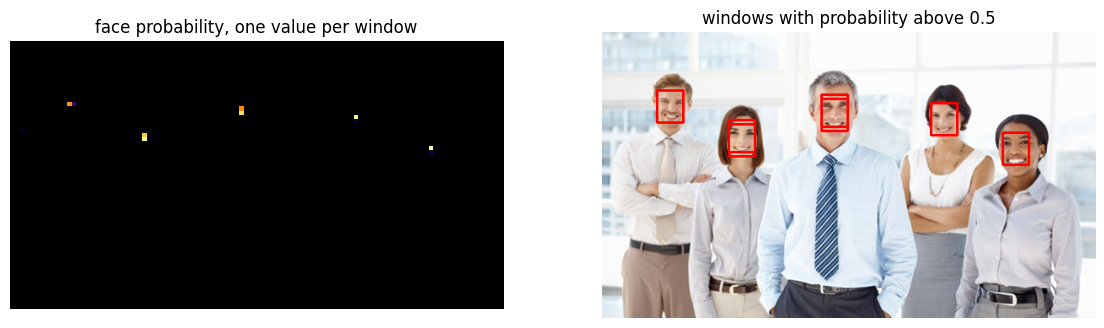

In [29]:
boxes = photo.copy()
for r, c in zip(*np.where(heat > 0.5)):
    y0, x0 = int(4 * r / scale), int(4 * c / scale)
    cv.rectangle(boxes, (x0, y0), (int(x0 + 25 / scale), int(y0 + 31 / scale)), (0, 0, 255), 2)
print('WINDOWS above 0.5:', int((heat > 0.5).sum()))

fig, axs = plt.subplots(1, 2, figsize=(14, 4.2))
axs[0].imshow(heat, cmap='inferno', vmin=0, vmax=1); axs[0].set_title('face probability, one value per window')
axs[1].imshow(cv.cvtColor(boxes, cv.COLOR_BGR2RGB)); axs[1].set_title('windows with probability above 0.5')
for ax in axs:
    ax.axis('off')
plt.show()

At `scale = 0.9` the network also finds all five faces, but at `0.6` or `1.0` only three of them (not the same three): the faces no longer have the size of the training crops. A real detector runs at several scales (an image pyramid) and merges overlapping boxes, which Lecture 16 covers.

## Try It Yourself

1. Change `nn.Conv2d(3, 6, 5)` to `nn.Conv2d(3, 6, 5, padding=2)`. Which shapes change, and what must `fc1` become? Use the formula before you run it.
2. Make the CNN wider, as the original PyTorch tutorial suggests: 32 filters in conv1 and 64 in conv2 (and `fc1` to match). How many parameters does it have now, how long does an epoch take, and what is the test accuracy?
3. Train the CNN with and without augmentation for 30 epochs. Plot both validation curves. When does augmentation start to pay off?
4. In the confusion matrix, which pair of classes is confused most? Show ten of those test photos. Would you get them right at 32 × 32 pixels?
5. Delete `nn.ReLU()` from the MLP (or `F.relu` from `Net.forward`) and retrain. What happens to the accuracy, and why (Lecture 13)?
6. Run the face FCN on `data/faces.jpg` at scales 0.6, 0.7, 0.8 and 0.9. Which faces does each scale find? Then try it on a photo of your own (resize it so that faces are about 31 pixels tall).